In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        k=0.01
        p=2
        if value < 0:
            return - abs((((1+k*value)**p)-1)/p)
        return (((1+k*value)**p)-1)/p
    
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(goal - abs(goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

### learner rewards

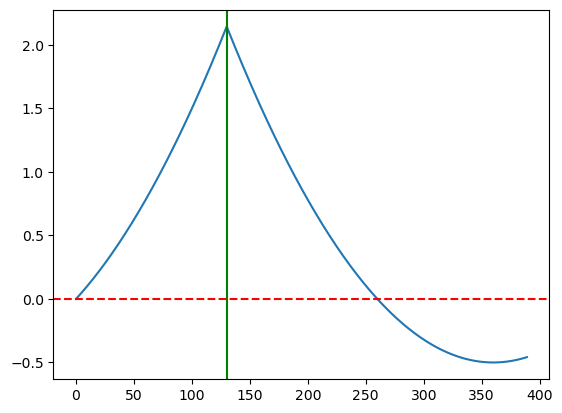

In [4]:
def increased_rewards(value):
    result=0
    k=0.01
    p=2
    if value < 0:
        return - abs((((1+k*value)**p)-1)/p)
    return (((1+k*value)**p)-1)/p
    
    
    if(value<0):
        for i in range(0,value,-1):
            result +=i/100
    else:
        for i in range(0,value):
            result +=i
    return result


values=[]
goal=130
for i in range(goal*3):
    values.append(increased_rewards(goal-abs(goal-i)))
plt.plot(values)
plt.axvline(x= goal,color ='g')
plt.axhline(y= 0,color ='r',linestyle = "dashed")
plt.savefig("SVG/GoalIncreasereward.svg")

### Test

In [5]:
episodeNumber=30000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
episodesTestResultsDeviation=[]
numberOfTest=50
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [6]:
goal=130

In [7]:
for episodeIndex in range(episodeNumber):
   
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    if(episodeIndex %500 ==0):
        qagent.epsilon=0
        testResultList=[]
        for episodeIndex in range(numberOfTest):
    
            state,_=env.reset()
            state=treatState(state)
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=treatState(next_state)
                state=next_state
                if (terminated):
                    testResultList.append(timeIndex)
                    break

        episodesTestResults.append(sum(testResultList)/len(testResultList))
        episodesTestResultsDeviation.append(np.std(episodesTestResults))
        qagent.epsilon=0.1
    


env.close() 

118.14436666666667


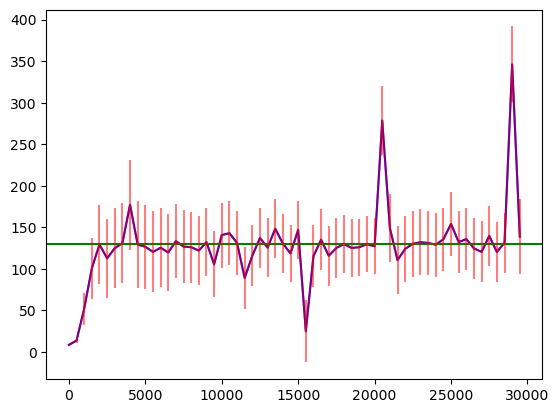

In [8]:
x=[]
for i in range(len(episodesTestResults)):
    x.append(i*500)
plt.plot(x,episodesTestResults,color ='b')
plt.axhline(y= goal,color ='g')
plt.errorbar(x,episodesTestResults,yerr=episodesTestResultsDeviation,color ='r',alpha=0.5)
plt.savefig("SVG/GoalIncrease1.svg")
print(sum(episodesResults)/len(episodesResults))

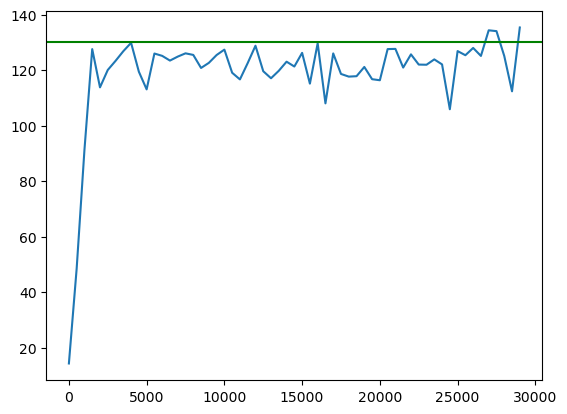

In [9]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)
x=[]
for i in range(len(previous100AveragePlot)):
    x.append(i*500)
plt.plot(x,previous100AveragePlot)
plt.axhline(y= goal,color ='g')
plt.savefig("SVG/GoalIncrease2.svg")

837


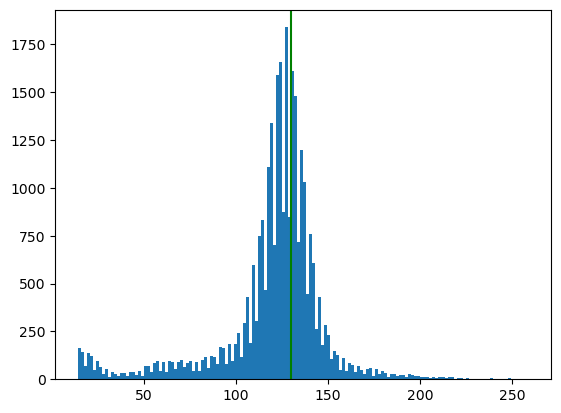

In [10]:
#histogram
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=150)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/GoalIncrease3.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

837


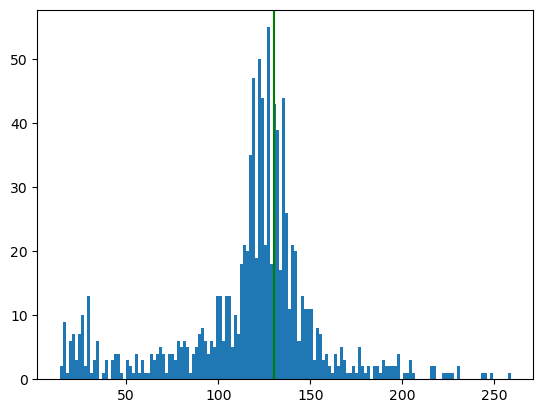

In [11]:
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers[-1000:],bins=150)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/GoalIncrease4.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

In [12]:
goal2LearnerEp=episodesResults
%store goal2LearnerEp
goal2learnerTestEp=episodesTestResults
%store goal2learnerTestEp
print(np.mean(episodesResults[-1000:]))
print(np.std(episodesResults[-1000:]))

Stored 'goal2LearnerEp' (list)
Stored 'goal2learnerTestEp' (list)
123.545
61.53585926108451


131.444
7.934914240242298


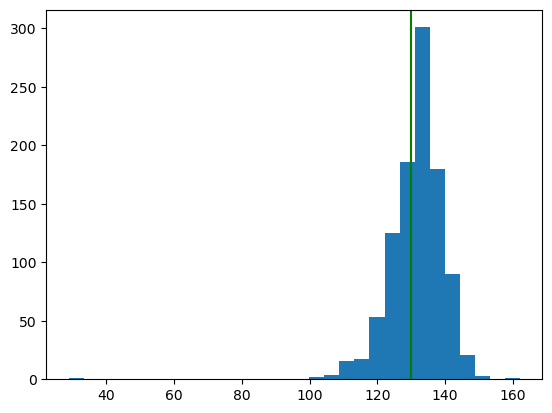

In [13]:
qagent.epsilon=0.05
last1000testList=[]
for episodeIndex in range(1000):
    
    state,_=env.reset()
    state=treatState(state)
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        state=next_state
        if (terminated):
            last1000testList.append(timeIndex)
            break



episodesResultswithoutOutliers=[]
for i in last1000testList:
    if i >goal -120 and i < goal+120:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=30)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/GoalIncreased5.svg")
print(np.mean(last1000testList))
print(np.std(last1000testList))

In [14]:
last1000testList2=last1000testList
%store last1000testList2

Stored 'last1000testList2' (list)


In [15]:
def uniTest(agent,epsilon=0):
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)


0.0
0.01
0.02
0.03
0.04
0.05
0.06
0.07
0.08
0.09
0.1
0.11
0.12
0.13
0.14
0.15
0.16
0.17
0.18
0.19
0.2
0.21
0.22
0.23
0.24
0.25
0.26
0.27
0.28
0.29
0.3
0.31
0.32
0.33
0.34
0.35
0.36
0.37
0.38
0.39
0.4
0.41
0.42
0.43
0.44
0.45
0.46
0.47
0.48
0.49
0.5
0.51
0.52
0.53
0.54
0.55
0.56
0.57
0.58
0.59
0.6
0.61
0.62
0.63
0.64
0.65
0.66
0.67
0.68
0.69
0.7
0.71
0.72
0.73
0.74
0.75
0.76
0.77
0.78
0.79
0.8
0.81
0.82
0.83
0.84
0.85
0.86
0.87
0.88
0.89
0.9
0.91
0.92
0.93
0.94
0.95
0.96
0.97
0.98
0.99


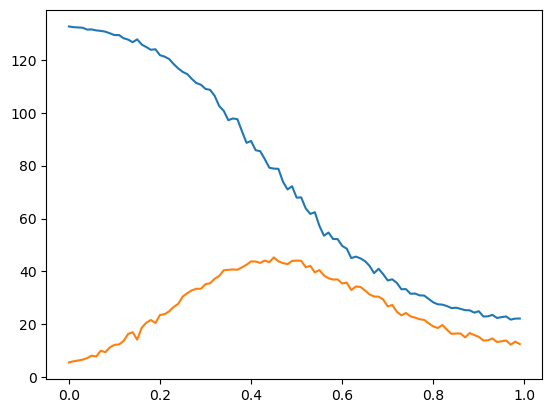

In [16]:
multimean=[]
multistd=[]
x=[]
division=100
for epsilon in range(0,division):
    x.append(epsilon/division)
    print(epsilon/division)
    tmpresult=uniTest(qagent,epsilon/division)
    multimean.append(tmpresult[0])
    multistd.append(tmpresult[1])
plt.plot(x,multimean)
plt.plot(x,multistd)

In [17]:
print(multimean)
print(multistd)

[132.65, 132.383, 132.29, 132.179, 131.475, 131.535, 131.158, 130.994, 130.68, 130.07, 129.398, 129.41, 128.211, 127.682, 126.701, 127.771, 125.794, 124.862, 123.823, 124.032, 121.78, 121.251, 120.355, 118.431, 116.801, 115.454, 114.641, 112.803, 111.237, 110.603, 109.013, 108.681, 106.43, 102.544, 100.739, 97.204, 97.853, 97.581, 93.029, 88.635, 89.335, 85.842, 85.481, 82.493, 79.226, 78.875, 78.795, 73.929, 71.008, 72.218, 67.905, 67.991, 63.823, 61.749, 62.384, 57.23, 53.492, 54.705, 52.251, 52.215, 49.648, 48.591, 45.031, 45.594, 44.935, 43.909, 42.116, 39.328, 40.989, 38.956, 36.562, 37.008, 35.644, 33.251, 33.298, 31.534, 31.626, 30.928, 30.87, 29.572, 28.29, 27.561, 27.43, 26.893, 26.121, 26.264, 25.827, 25.336, 25.269, 24.397, 24.931, 22.933, 22.995, 23.545, 22.383, 22.7, 22.957, 21.767, 22.141, 22.175]
[5.544682136966916, 5.996191374531003, 6.272312173353619, 6.606433152617227, 7.1829920645925815, 8.13232900219857, 7.795962801347887, 9.989092251050643, 9.43374792964069, 11.257